In [7]:
import os
# Tạo thư mục dataset và giải nén file vào đó
!mkdir -p dataset
# Đảm bảo file zip tồn tại trước khi giải nén
if os.path.exists('/content/CCCD_Detection.v1i.yolov8.zip'):
    !unzip -q /content/CCCD_Detection.v1i.yolov8.zip -d /content/dataset
    print("Giải nén thành công!")
else:
    print("Lỗi: Không tìm thấy file /content/CCCD_Detection.v1i.yolov8.zip. Hãy đảm bảo bạn đã upload file này lên thư mục /content.")

Giải nén thành công!


In [4]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.5 MB/s eta 0:00:00


In [8]:
import yaml

# Đường dẫn tới file data.yaml sau khi giải nén
yaml_path = '/content/dataset/data.yaml'

if os.path.exists(yaml_path):
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)

    # Cập nhật đường dẫn tuyệt đối cho Colab
    data['train'] = '/content/dataset/train/images'
    data['val'] = '/content/dataset/valid/images'
    if 'test' in data:
        data.pop('test') # Xóa test cũ để tránh nhầm lẫn

    # Lưu đè lại file data.yaml
    with open(yaml_path, 'w') as f:
        yaml.dump(data, f, default_flow_style=False)

    print("Đã cập nhật data.yaml thành công:")
    print(data)
else:
    print("Lỗi: Không tìm thấy file data.yaml để cập nhật.")

Đã cập nhật data.yaml thành công:
{'train': '/content/dataset/train/images', 'val': '/content/dataset/valid/images', 'nc': 12, 'names': ['date_of_birth', 'date_of_expiry', 'gender', 'hometown', 'hometown_2', 'id', 'image', 'name', 'nation', 'permanent_residence', 'permanent_residence_1', 'permanent_residence_2'], 'roboflow': {'workspace': 'dangthanhhieus-workspace', 'project': 'cccd_detection-nejqz-r31ac', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/dangthanhhieus-workspace/cccd_detection-nejqz-r31ac/dataset/1'}}


In [9]:
from ultralytics import YOLO

# Khởi tạo lại mô hình từ trọng số gốc
model = YOLO('yolo11n.pt')

# Tiến hành huấn luyện nâng cao với các tham số tối ưu cho chữ nhỏ
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=100,          # Tăng số vòng lặp để model hội tụ tốt hơn
    imgsz=1024,          # Cực kỳ quan trọng để thấy chữ nhỏ
    batch=8,             # Giảm nhẹ batch size để tránh tràn bộ nhớ GPU ở 1024px
    device=0,
    patience=30,         # Tăng kiên nhẫn lên 30
    optimizer='AdamW',   # Tốt cho việc học các đặc trưng text
    lr0=0.001,
    augment=True,
    mosaic=1.0,
    mixup=0.1,
    project='cccd_retrain',
    name='v2_img1024'
)

Ultralytics 8.4.22 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=v2_img10242, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=30, perspectiv

In [13]:
from google.colab import files
import os

# Đường dẫn chính xác từ log của bạn
best_weights = '/content/runs/detect/cccd_retrain/v2_img10242/weights/best.pt'

if os.path.exists(best_weights):
    print("Đã tìm thấy mô hình v2! Đang tải về...")
    files.download(best_weights)
else:
    print("Vẫn không thấy? Để tôi tìm đường dẫn thực tế cho bạn:")
    !find /content/runs -name "best.pt"

Đã tìm thấy mô hình v2! Đang tải về...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


image 1/1 /content/cccdt.jpg: 672x1024 1 date_of_birth, 1 date_of_expiry, 1 gender, 2 hometowns, 1 id, 1 name, 1 nation, 3 permanent_residences, 79.0ms
Speed: 9.7ms preprocess, 79.0ms inference, 1.7ms postprocess per image at shape (1, 3, 672, 1024)


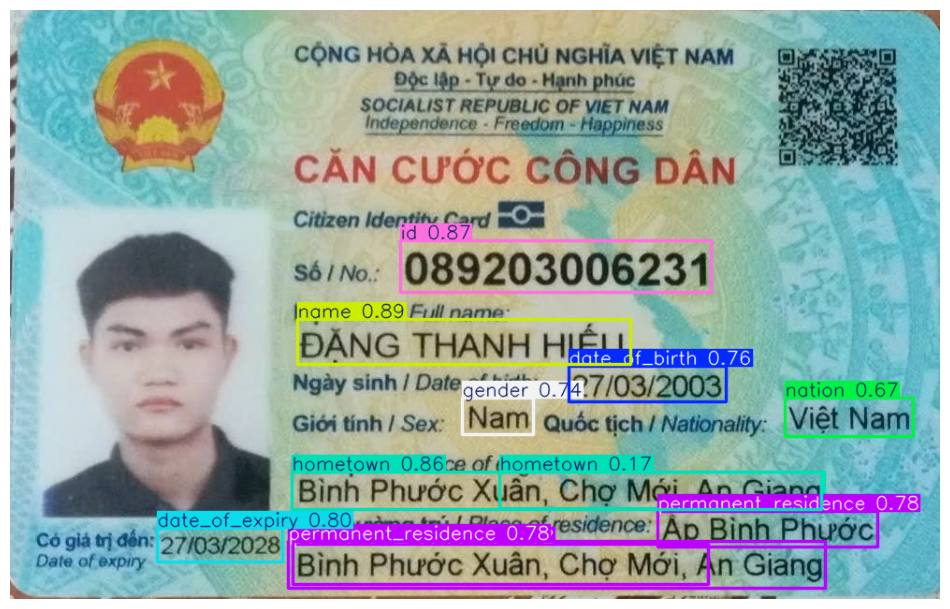

--- Chi tiết kết quả detect ---
Lớp: name                 | Độ tự tin: 0.89
Lớp: id                   | Độ tự tin: 0.87
Lớp: hometown             | Độ tự tin: 0.86
Lớp: date_of_expiry       | Độ tự tin: 0.80
Lớp: permanent_residence  | Độ tự tin: 0.78
Lớp: permanent_residence  | Độ tự tin: 0.78
Lớp: date_of_birth        | Độ tự tin: 0.76
Lớp: gender               | Độ tự tin: 0.74
Lớp: nation               | Độ tự tin: 0.67
Lớp: permanent_residence  | Độ tự tin: 0.52
Lớp: hometown             | Độ tự tin: 0.17


In [14]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import os

# 1. Load model best.pt
model_path = '/content/runs/detect/cccd_retrain/v2_img10242/weights/best.pt'
if os.path.exists(model_path):
    model = YOLO(model_path)

    # 2. Dự đoán ảnh cccdt.jpg
    source_img = '/content/cccdt.jpg'
    results = model.predict(source=source_img, conf=0.1, save=False)

    # 3. Hiển thị kết quả bằng matplotlib
    for r in results:
        im_array = r.plot()  # Vẽ các box và label
        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(im_array, cv2.COLOR_BGR2RGB))
        plt.axis('off')
        plt.show()

    # 4. In thông tin chi tiết các lớp phát hiện được
    print("--- Chi tiết kết quả detect ---")
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf_score = float(box.conf[0])
        print(f"Lớp: {model.names[class_id]:<20} | Độ tự tin: {conf_score:.2f}")
else:
    print("Không tìm thấy file best.pt trong thư mục /content. Hãy đảm bảo bạn đã tải lên hoặc huấn luyện xong.")